# 05 · Previsões com o modelo vigente e comparação entre ciclos

O modelo vigente é carregado do armazenamento persistente **com** o pré-processamento e as features eleitas (tudo no mesmo `Pipeline`). As previsões são feitas para os clientes da **próxima campanha**: o lote que ainda não chegou ao pipeline e, portanto, não participou da escolha do modelo.

**Política de negócio:** o banco liga para os 20% de clientes com maior probabilidade de contratar.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.promocao import carregar_vigente, HISTORICO_DECISOES
from src.ingestao import lote_pendente
from src.preprocessamento import limpar_e_criar_atributos, separar_xy
from src.modelagem import calcular_metricas

ctx = ler_contexto(cfg)
vigente, manifesto = carregar_vigente()
assert list(vigente.named_steps["selecao"].features) == manifesto["features"], "Modelo e manifesto divergentes"
print(f"Modelo vigente: {manifesto['algoritmo']} do ciclo {manifesto['cycle_id']} (run {manifesto['run_id']})")
print("Features:", manifesto["features"])

Modelo vigente: random_forest do ciclo c005-20261120-1906 (run 900278bf92044d54bb8ae8f479931025)
Features: ['euribor3m', 'cons.price.idx', 'emp.var.rate', 'poutcome', 'month', 'contact', 'cons.conf.idx', 'nr.employed']


In [3]:
pendente = lote_pendente(cfg)
if pendente is not None:
    origem = f"próxima campanha (períodos {sorted(pendente['periodo'].unique())})"
    novos = limpar_e_criar_atributos(pendente, cfg)
else:
    origem = "teste reservado (fonte esgotada, sem campanha futura)"
    novos = pd.read_csv(caminho(cfg["dados"]["processed_dir"]) / "teste.csv")
X_novos, y_novos = separar_xy(novos, cfg)
proba = vigente.predict_proba(X_novos)[:, 1]

pct = cfg["negocio"]["percentual_contato"]
prev = novos[["registro_id", "periodo", "age", "job", "contact"]].copy()
prev["probabilidade_adesao"] = proba.round(4)
prev["ranking"] = prev["probabilidade_adesao"].rank(ascending=False, method="first").astype(int)
prev["ligar"] = prev["ranking"] <= int(len(prev) * pct)
prev = prev.sort_values("ranking")
print(f"Origem: {origem} | {len(prev)} clientes | {prev['ligar'].sum()} na lista de ligação")
display(prev.head(15))

Origem: próxima campanha (períodos ['2010-04', '2010-05', '2010-06']) | 615 clientes | 123 na lista de ligação


,registro_id,periodo,age,job,contact,probabilidade_adesao,ranking,ligar
0,39394,2010-04,60,housemaid,cellular,0.9309,1,True
2,39396,2010-04,33,admin.,cellular,0.9309,2,True
13,39407,2010-04,46,technician,cellular,0.9309,3,True
14,39408,2010-04,27,admin.,cellular,0.9309,4,True
34,39428,2010-04,58,housemaid,cellular,0.9309,5,True
35,39429,2010-04,62,entrepreneur,cellular,0.9309,6,True
36,39430,2010-04,58,housemaid,cellular,0.9309,7,True
38,39432,2010-04,48,admin.,cellular,0.9309,8,True
39,39433,2010-04,49,admin.,cellular,0.9309,9,True
42,39436,2010-04,58,housemaid,cellular,0.9309,10,True


### O que teria acontecido? (os rótulos reais existem porque a campanha é histórica)

In [4]:
m = calcular_metricas(y_novos, proba, pct)
impacto = pd.DataFrame({
    "Ligar para todos": {"ligações": len(prev), "adesões": int(y_novos.sum()), "conversão": y_novos.mean()},
    f"Ligar para top {int(pct*100)}% (modelo)": {"ligações": int(prev["ligar"].sum()),
        "adesões": int(round(m["captura_top"] * y_novos.sum())), "conversão": m["conversao_top"]},
})
display(impacto.T.style.format({"conversão": "{:.1%}", "ligações": "{:,.0f}", "adesões": "{:,.0f}"}))
print(f"Com {int(pct*100)}% das ligações, o modelo captura {m['captura_top']:.0%} das adesões (lift {m['lift_top']:.1f}x).")

,ligações,adesões,conversão
Ligar para todos,615,326,53.0%
Ligar para top 20% (modelo),123,86,69.9%


Com 20% das ligações, o modelo captura 26% das adesões (lift 1.3x).


In [5]:
ev = caminho("evidencias") / ctx["cycle_id"]; ev.mkdir(parents=True, exist_ok=True)
prev.to_csv(ev / "previsoes.csv", index=False)
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"{ctx['cycle_id']}_05_previsoes", tags=tags_ciclo(ctx, "05_previsoes")):
    mlflow.log_params({"origem_previsoes": origem, "modelo_vigente_cycle": manifesto["cycle_id"], "modelo_vigente_run": manifesto["run_id"]})
    mlflow.log_metrics({f"previsao_{k}": v for k, v in m.items()})
    mlflow.log_artifact(str(ev / "previsoes.csv"))

## Comparação entre ciclos

In [6]:
hist = pd.read_csv(caminho(HISTORICO_DECISOES))
metrica = cfg["avaliacao"]["metrica_principal"]
display(hist[["cycle_id", "gatilho", "data_version", "linhas_lote", "n_features", "cv_A", "cv_B", "vencedor",
              f"candidato_val_{metrica}", f"vigente_anterior_val_{metrica}", "decisao", "vigente_apos", "drift_alerta"]].round(4))

,cycle_id,gatilho,data_version,linhas_lote,n_features,cv_A,cv_B,vencedor,candidato_val_average_precision,vigente_anterior_val_average_precision,decisao,vigente_apos,drift_alerta
0,c001-20261116-2102,schedule,v001-44df464c,27680,8,0.0902,0.1004,B-random_forest,0.1045,NaN,PROMOVIDO,c001-20261116-2102-random_forest,False
1,c002-20261117-1951,schedule,v002-db4f8bd6,2750,8,0.1917,0.2058,B-random_forest,0.2043,0.1067,PROMOVIDO,c002-20261117-1951-random_forest,True
2,c003-20261118-1924,schedule,v003-31eeff6c,6687,8,0.2341,0.2348,B-random_forest,0.2555,0.2224,PROMOVIDO,c003-20261118-1924-random_forest,True
3,c004-20261119-1929,schedule,v004-ce2b8d77,1484,8,0.2982,0.3015,B-random_forest,0.3209,0.2818,PROMOVIDO,c004-20261119-1929-random_forest,True
4,c005-20261120-1906,schedule,v005-0c33f7d6,793,8,0.3480,0.3615,B-random_forest,0.3628,0.3470,PROMOVIDO,c005-20261120-1906-random_forest,True


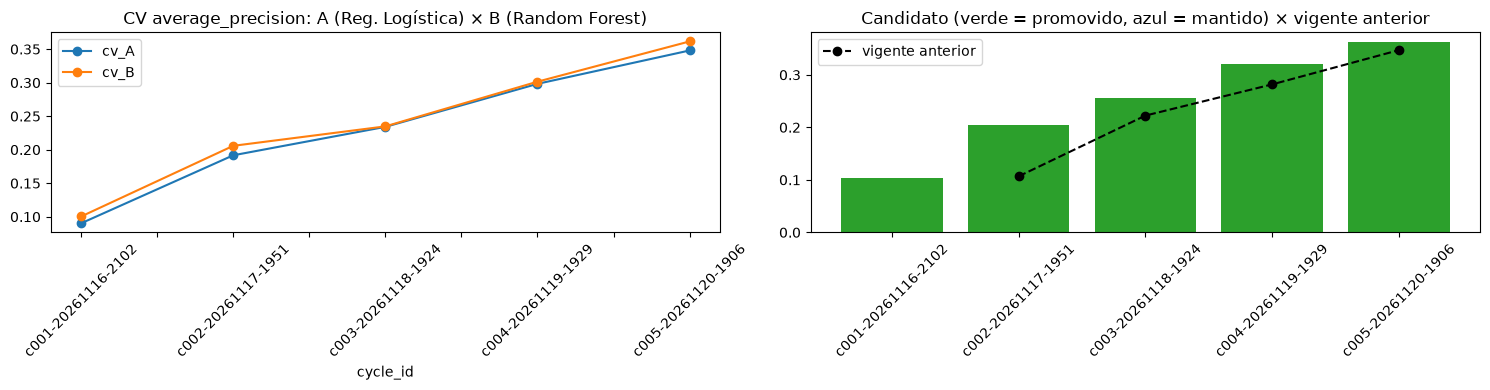

Ciclos em que o conjunto de features mudou: ['c001-20261116-2102', 'c002-20261117-1951', 'c003-20261118-1924', 'c004-20261119-1929', 'c005-20261120-1906']


In [7]:
if len(hist) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    hist.plot(x="cycle_id", y=["cv_A", "cv_B"], marker="o", ax=ax[0], title=f"CV {metrica}: A (Reg. Logística) × B (Random Forest)")
    cores = hist["decisao"].map({"PROMOVIDO": "#2ca02c", "MANTIDO": "#1f77b4", "REJEITADO": "#d62728"})
    ax[1].bar(hist["cycle_id"], hist[f"candidato_val_{metrica}"], color=cores)
    ax[1].plot(hist["cycle_id"], hist[f"vigente_anterior_val_{metrica}"], "ko--", label="vigente anterior")
    ax[1].set_title("Candidato (verde = promovido, azul = mantido) × vigente anterior"); ax[1].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

    mudou = hist["features_eleitas"].ne(hist["features_eleitas"].shift())
    print("Ciclos em que o conjunto de features mudou:", hist.loc[mudou, "cycle_id"].tolist())

In [8]:
# Histórico consultável no MLflow: todos os runs de todos os ciclos
mlflow = configurar_mlflow(cfg)
runs = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experimento"]], order_by=["start_time ASC"])
cols = [c for c in ["tags.cycle_id", "tags.etapa", "tags.data_version", "tags.gatilho", "params.algoritmo",
                    f"metrics.cv_{metrica}_media", "params.decisao", "run_id"] if c in runs.columns]
display(runs[cols].tail(20))

,tags.cycle_id,tags.etapa,tags.data_version,tags.gatilho,params.algoritmo,metrics.cv_average_precision_media,params.decisao,run_id
10,c002-20261117-1951,04_promocao,v002-db4f8bd6,schedule,NaN,NaN,PROMOVIDO,559ce72fad6c46a6862a5f5f2141eb78
11,c002-20261117-1951,05_previsoes,v002-db4f8bd6,schedule,NaN,NaN,NaN,abf54b5205a345a883ecfed3dc6371a4
12,c003-20261118-1924,01_etl,v003-31eeff6c,schedule,NaN,NaN,NaN,3d95813af8794bb3ba4de1f8447880ab
13,c003-20261118-1924,02_votacao,v003-31eeff6c,schedule,NaN,NaN,NaN,5348bd3e693b4cf3895fcdffb97246e3
14,c003-20261118-1924,03_treino,v003-31eeff6c,schedule,regressao_logistica,0.234072,NaN,ed065f7fcb294320bed8a153f46b223c
15,c003-20261118-1924,03_treino,v003-31eeff6c,schedule,random_forest,0.234779,NaN,ea7e35d29be448398554d6a8f065f828
16,c003-20261118-1924,04_promocao,v003-31eeff6c,schedule,NaN,NaN,PROMOVIDO,776a93e80ee54b5bbdaa3585bd9b94b8
17,c003-20261118-1924,05_previsoes,v003-31eeff6c,schedule,NaN,NaN,NaN,fc7ffbcb8a4549398faef597cf72ee81
18,c004-20261119-1929,01_etl,v004-ce2b8d77,schedule,NaN,NaN,NaN,c98d641b168042578b2e6fc1d7c0d018
19,c004-20261119-1929,02_votacao,v004-ce2b8d77,schedule,NaN,NaN,NaN,36b8bcc3881f432aa6b7445572fa9894
